#### This code is creating and analysing a synthetic dataset for simple feline acne DAG using dagitty. It also pulls in results on analysis on gendata datasets.

In [7]:
# if not yet installed, install the required packages
# packgs <- c('ggplot2','dagitty','lme4','corrplot','semPlot','stringr','boot')
# install.packages(packgs)

In [8]:
rm(list=ls()) 
library(ggplot2)
library(dagitty)
library(lme4)
library(corrplot)
library(semPlot)
library(stringr)
library(boot)
# source the file with functions used in the project, includes DAG definitions:
# dag - dag definition
# functions: GenData, Factor.Analysis, reorder_mat, get_prevalence, createT2
source('0_supporting_functions.r')

Loading required package: Matrix

corrplot 0.92 loaded



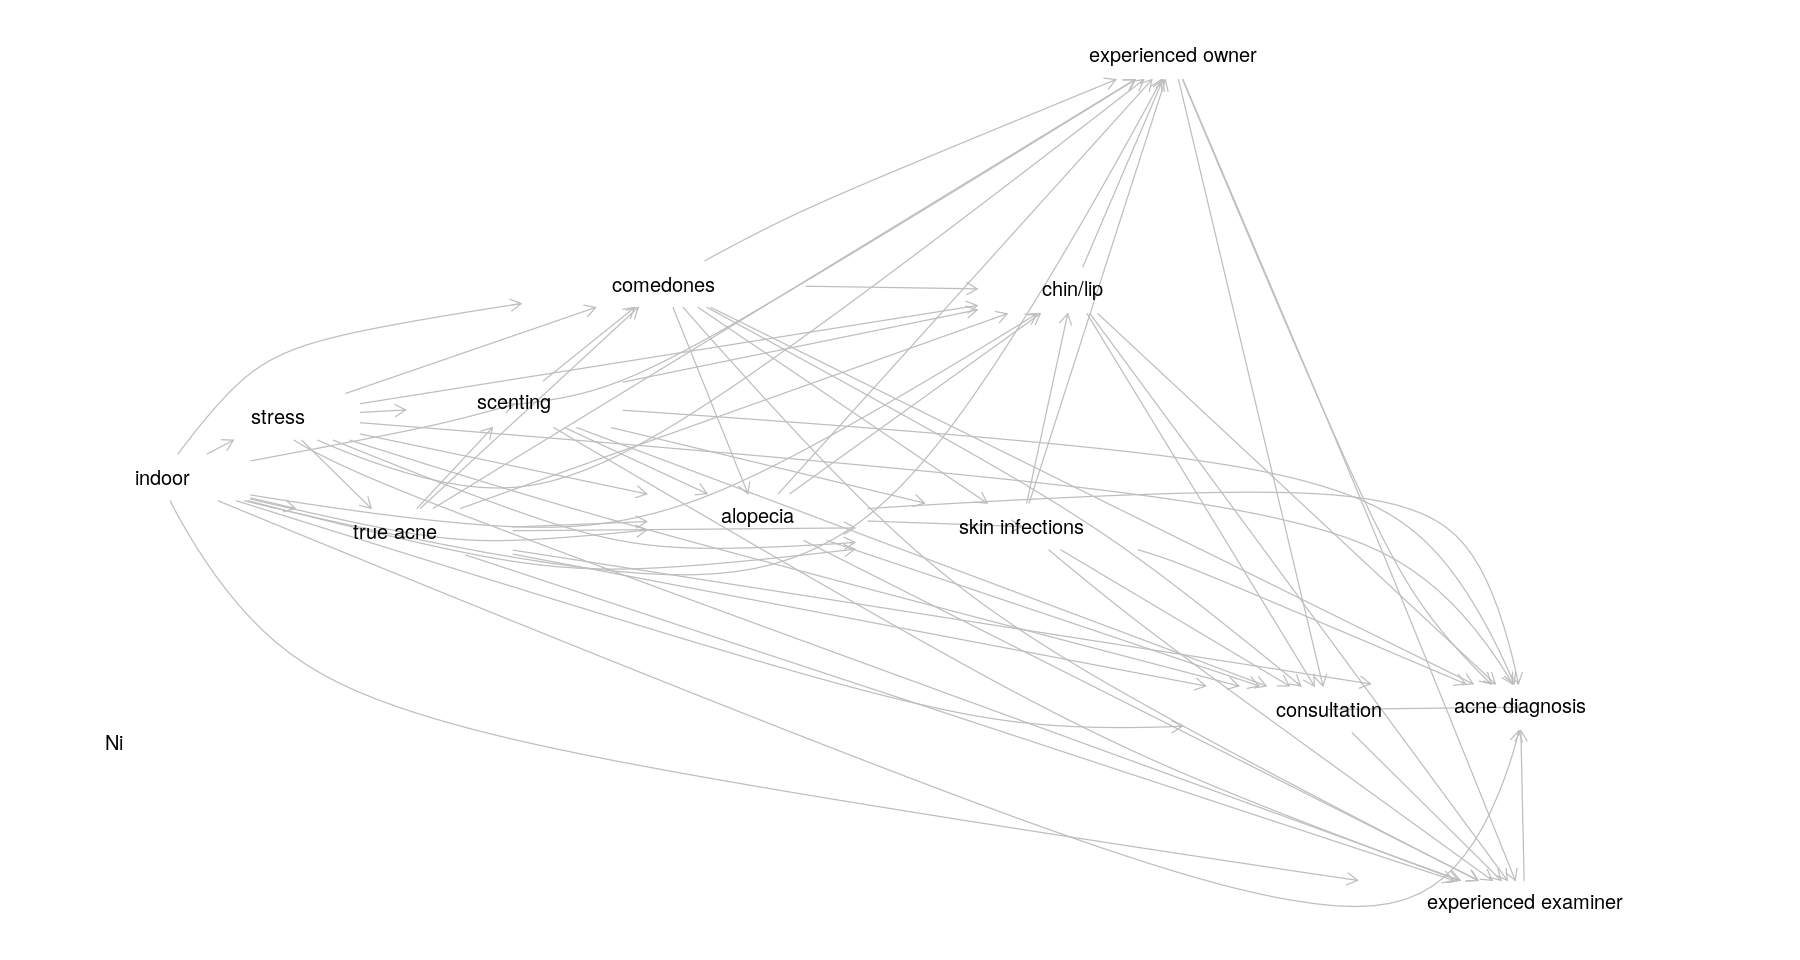

In [10]:
options(repr.plot.width=15, repr.plot.height=8)
# the plot can include path coefficients but it might be busy
# plot(dag, show.coefficients=TRUE)
plot(dag)

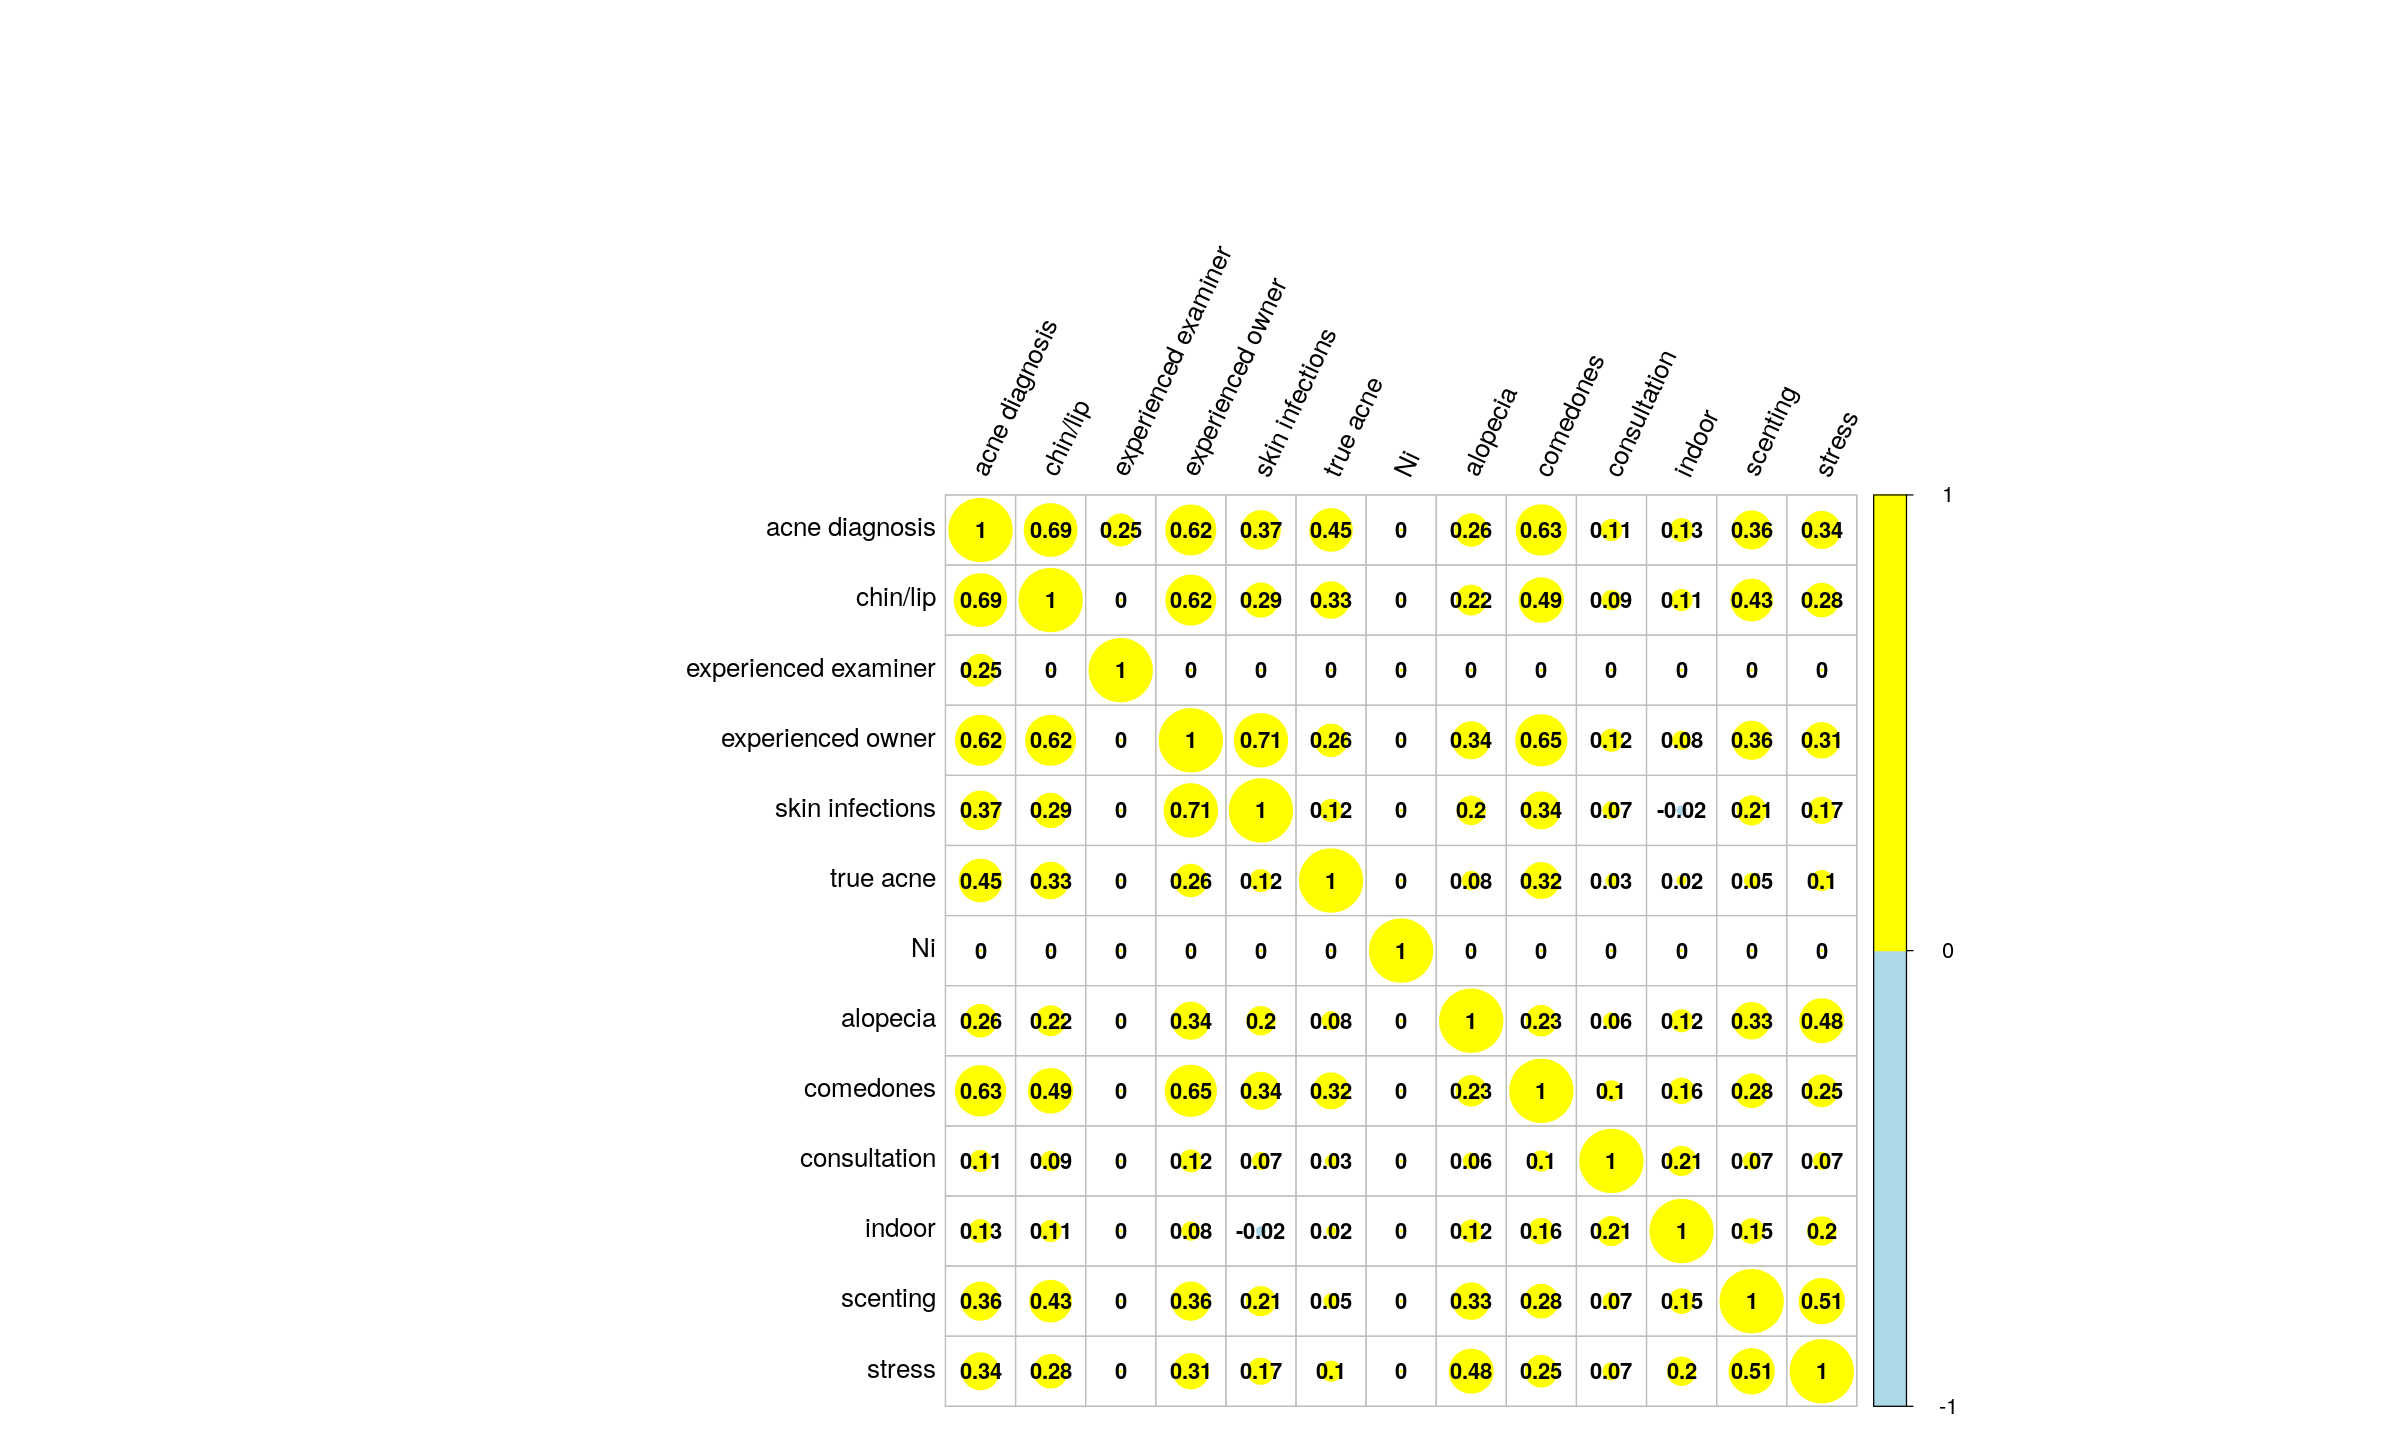

In [11]:
N <- 100000 # number of data points
mydataSEM <- simulateSEM(dag, N=N, empirical=TRUE, b.default=0) # Gaussian dagitty dataset

# correlation matrix
options(repr.plot.width=20, repr.plot.height=12)
corrplot(round(cor(mydataSEM),2), addCoef.col = "black", tl.col="black", col=c("lightblue", "yellow"),
        tl.cex = 1.3, number.cex = 1.1, cl.cex = 1.1, tl.srt = 65)

##### <span style="color:blue">This section uses covariate Ni to generate clustering and examiner's experience; it is divided into six steps; N/C must be an integer but the code can be improved to skip that requirement</span>

In [12]:
C <- 50 # number of examiners
sdev_examiners <- 0.9 # standard deviation of the number of consultations per examiner
mean_examiners <- 1.2 # mean of the number of consultations per examiner
if (floor(N/C)!=ceiling(N/C)) print('Make sure N/C is an integer!')

In [13]:
# 1. order Ni ascending
Nhat <- mydataSEM$Ni[order(mydataSEM$Ni)]

In [14]:
# 2. rescale, with mean and standard deviation as defined above
Nhat <- Nhat*sdev_examiners + mean_examiners
# exponentiate to get the lognormal distribution 'back'
Nhat <- exp(Nhat)

In [15]:
# 3. divide the vector into C equal-size subgroups by creating 'subgroup' column
Nhat <- data.frame(Nhat)
Nhat$subgroup <- rep(1:C, each=N/C)

In [16]:
# 4. select 1 value in each subgroup and round it to the nearest integer to get C numbers of cluster size (Njhat)
select_rows <- runif(C)*N/C
# add a vector of 1, 2001, 4001,...
select_rows <- select_rows + seq(1,length.out = length(select_rows), by=N/C)
select_rows <- round(select_rows,0)
Njhat <- Nhat[select_rows,]
Njhat$Nhat <- round(Njhat$Nhat,0)
rm(select_rows)
rm(Nhat)

In [17]:
# 5. make Njhat sum to the population size by adding +/- 1 randomly -> Nj
while (N-sum(Njhat$Nhat)!=0)
{
    sample_rows <- sample(1:nrow(Njhat), size=min(abs(N-sum(Njhat$Nhat)),nrow(Njhat)))
    Njhat[sample_rows, 'Nhat'] <- Njhat[sample_rows, 'Nhat'] + 1*if(N-sum(Njhat$Nhat)<0){-1}else{1}
}
Nj <- Njhat$Nhat
rm(Njhat)

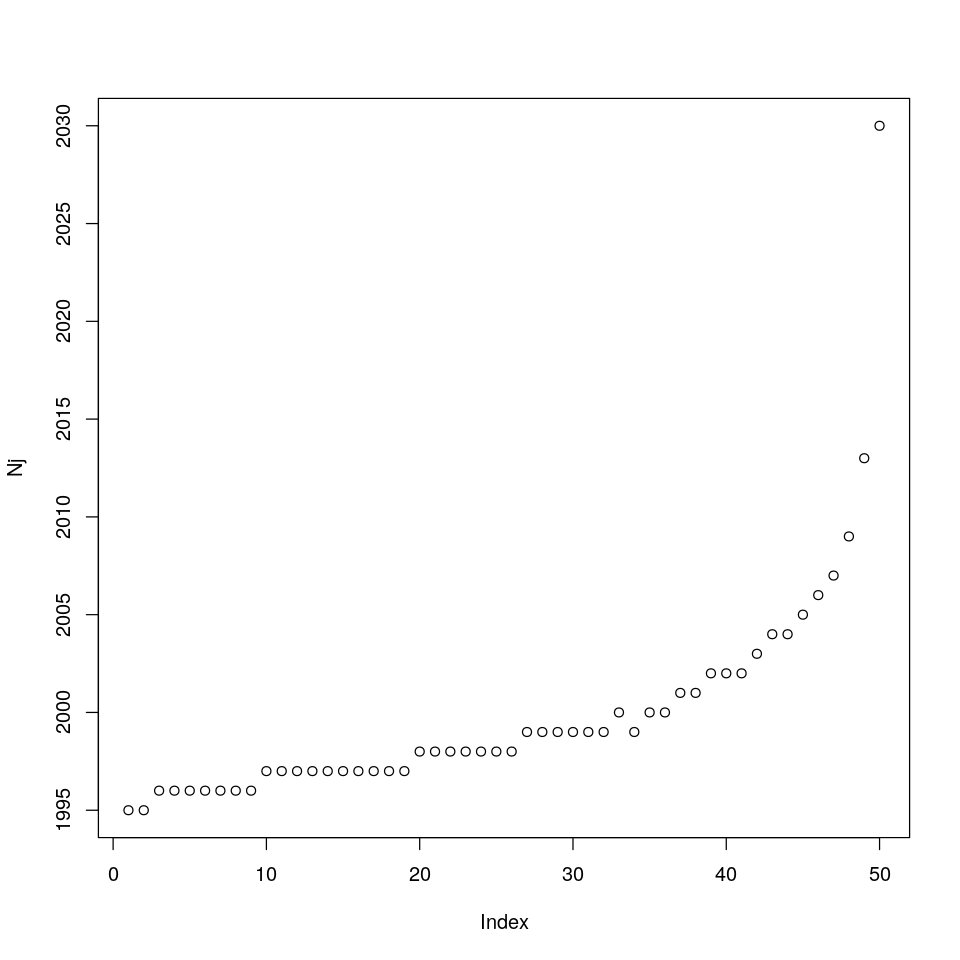

In [18]:
# 6. divide original Ni into C clusters of size Nj, j=1,2,...,C
mydataSEM <- mydataSEM[order(mydataSEM$Ni),]

Nj <- round(Nj/sum(Nj)*N,0)
# randomly +/-1 if sum(Nj)!=N
while (N-sum(Nj)!=0)
{
    sample_rows <- sample(1:length(Nj), size=min(abs(N-sum(Nj)),length(Nj)))
    Nj[sample_rows] <- Nj[sample_rows] + 1*if(N-sum(Nj)<0){-1}else{1}
}
options(repr.plot.width=8, repr.plot.height=8)
plot(Nj)

In [19]:
# 6. continued
mydataSEM$cluster <- rep(1:C,Nj)

In [20]:
Nj

[1] 1995 1995 1996 1996 1996 1996 1996 1996 1996 1997 1997 1997 1997 1997 1997
[16] 1997 1997 1997 1997 1998 1998 1998 1998 1998 1998 1998 1999 1999 1999 1999
[31] 1999 1999 2000 1999 2000 2000 2001 2001 2002 2002 2002 2003 2004 2004 2005
[46] 2006 2007 2009 2013 2030

In [21]:
rm(Nj)

In [22]:
# average by cluster
mydataSEM$'experienced examiner j' <- ave(mydataSEM$'experienced examiner', mydataSEM$cluster, FUN = mean, na.rm = TRUE)

In [23]:
head(mydataSEM)

,acne diagnosis,chin/lip,experienced examiner,experienced owner,skin infections,true acne,Ni,alopecia,comedones,consultation,indoor,scenting,stress,cluster,experienced examiner j
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
13039,1.1560822,-0.2380833,0.4647316,0.7880560,0.9726134,0.6654720,-4.420165,0.8112204,2.1005042,-1.5770536,0.2327402,-0.2862519,1.1828987,1,0.02108631
50429,-2.2701552,-2.0700715,0.9268760,-1.8491307,-0.3974283,-1.4143757,-4.152006,0.2251419,-2.3729366,-1.6973201,1.3663469,-0.7326201,-0.4688484,1,0.02108631
31043,0.9821539,1.1066462,-0.5019691,1.2360369,0.9135879,0.5501824,-4.080555,0.3292358,-0.3795388,-0.2365963,0.1925855,0.9913373,0.3062431,1,0.02108631
59637,1.2494750,0.7664478,-0.4718559,1.7240864,-0.4034282,0.9911193,-4.020185,-0.4011398,2.0800681,0.1533893,0.4761613,0.1417887,-0.6966537,1,0.02108631
19664,-0.6603395,-2.1819463,0.6361014,-0.5110922,0.2984256,0.1878636,-4.000241,1.2831539,-0.3739289,-0.7778126,0.2556406,-0.5067686,0.5723086,1,0.02108631
32997,0.2775379,1.4121452,0.7594057,0.2383874,0.5076316,-0.6655060,-3.947661,0.5822418,-2.0187832,-0.7730634,0.6904254,2.1499554,0.8720434,1,0.02108631


#### dichotomise the covariates

In [24]:
mydataSEM <- mydataSEM[order(mydataSEM$'acne diagnosis',decreasing = TRUE),]
percent_of1s <- 0.28
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'acne diagnosis' <- 0
mydataSEM[1:num_rows_of1s,'acne diagnosis'] <- 1

In [25]:
mydataSEM <- mydataSEM[order(mydataSEM$'chin/lip',decreasing = TRUE),]
percent_of1s <- 3
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'chin/lip' <- 0
mydataSEM[1:num_rows_of1s,'chin/lip'] <- 1

In [26]:
mydataSEM <- mydataSEM[order(mydataSEM$'experienced owner',decreasing = TRUE),]
percent_of1s <- 34
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'experienced owner' <- 0
mydataSEM[1:num_rows_of1s,'experienced owner'] <- 1

In [27]:
mydataSEM <- mydataSEM[order(mydataSEM$'skin infections',decreasing = TRUE),]
percent_of1s <- 2
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'skin infections' <- 0
mydataSEM[1:num_rows_of1s,'skin infections'] <- 1

In [28]:
mydataSEM <- mydataSEM[order(mydataSEM$'true acne',decreasing = TRUE),]
percent_of1s <- 5
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'true acne' <- 0
mydataSEM[1:num_rows_of1s,'true acne'] <- 1

In [29]:
mydataSEM <- mydataSEM[order(mydataSEM$'alopecia',decreasing = TRUE),]
percent_of1s <- 1
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'alopecia' <- 0
mydataSEM[1:num_rows_of1s,'alopecia'] <- 1

In [30]:
mydataSEM <- mydataSEM[order(mydataSEM$'comedones',decreasing = TRUE),]
percent_of1s <- 3
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'comedones' <- 0
mydataSEM[1:num_rows_of1s,'comedones'] <- 1

In [31]:
mydataSEM <- mydataSEM[order(mydataSEM$'consultation',decreasing = TRUE),]
percent_of1s <- 21.7
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'consultation' <- 0
mydataSEM[1:num_rows_of1s,'consultation'] <- 1

In [32]:
mydataSEM <- mydataSEM[order(mydataSEM$'indoor',decreasing = TRUE),]
percent_of1s <- 26.1
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'indoor' <- 0
mydataSEM[1:num_rows_of1s,'indoor'] <- 1

In [33]:
mydataSEM <- mydataSEM[order(mydataSEM$'scenting',decreasing = TRUE),]
percent_of1s <- 25
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'scenting' <- 0
mydataSEM[1:num_rows_of1s,'scenting'] <- 1

In [34]:
mydataSEM <- mydataSEM[order(mydataSEM$'stress',decreasing = TRUE),]
percent_of1s <- 25
num_rows_of1s <- round(percent_of1s*N/100,0)
mydataSEM$'stress' <- 0
mydataSEM[1:num_rows_of1s,'stress'] <- 1

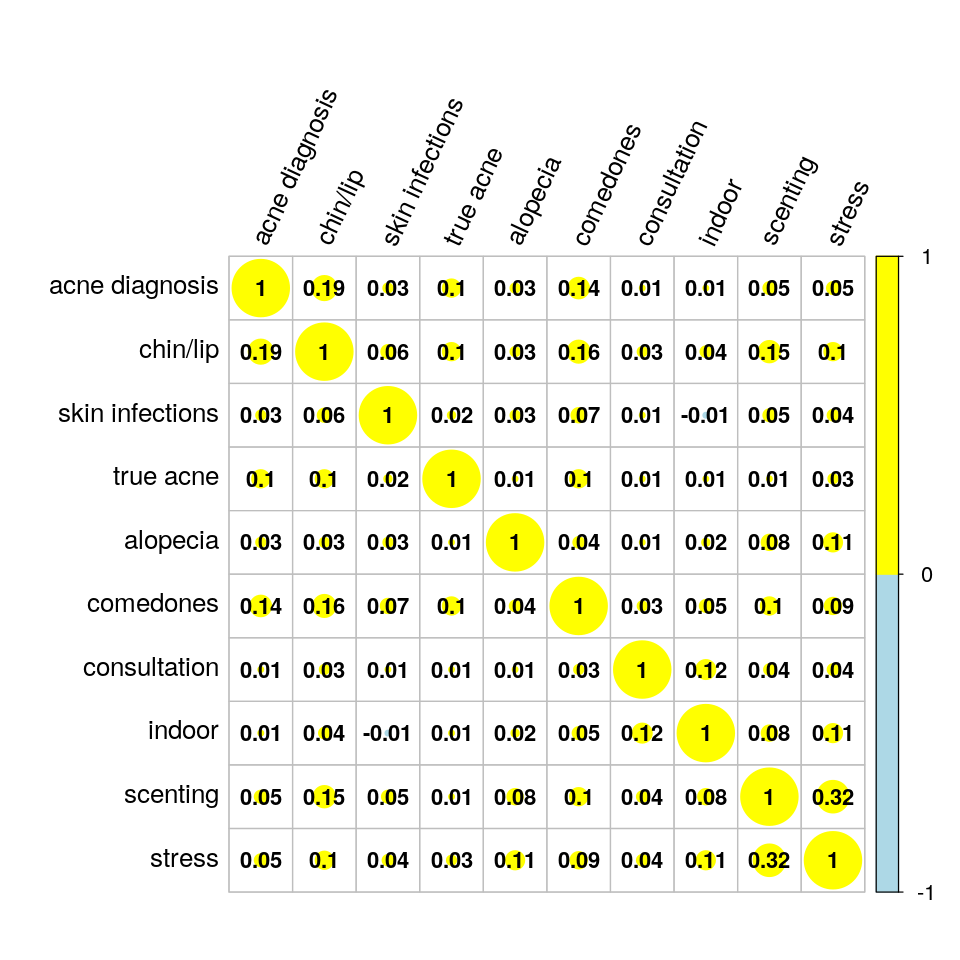

In [35]:
options(repr.plot.width=8, repr.plot.height=8)
corrplot(round(cor(mydataSEM[,c('acne diagnosis','chin/lip',
                                   'skin infections','true acne','alopecia',
                                   'comedones','consultation','indoor','scenting','stress')]),2),
         addCoef.col = "black", tl.col="black", col=c("lightblue", "yellow"),
        tl.cex = 1.3, number.cex = 1.1, cl.cex = 1.1, tl.srt = 65)

#### table 2 on dichotomised

In [36]:
# solvers don't like names with spaces
names2change <- colnames(mydataSEM)
new_names <- str_replace(names2change, " ", "_")
new_names <- str_replace(new_names, " ", "_")
new_names <- str_replace(new_names, " ", "_")
new_names <- str_replace(new_names, "/", "_")
colnames(mydataSEM) <- new_names

In [37]:
# data for pets that have had a consultation
mydata_consult1 <- mydataSEM[mydataSEM$consultation==1,]

##### example 1) outcome: consultation

In [38]:
# whole population T2, no examiner experience, no cluster
m1  <-   glm(consultation ~ 1 
             + experienced_owner   
             + chin_lip     
             + skin_infections       
             + alopecia       
             + comedones           
             + scenting     
             + stress         
             + indoor,
             data = mydataSEM, family = binomial)

m2  <-   glm(consultation ~ 1 
             + chin_lip     
             + skin_infections       
             + alopecia       
             + comedones           
             + scenting     
             + stress         
             + indoor,
             data = mydataSEM, family = binomial)

m3  <-   glm(consultation ~ 1 
             + skin_infections       
             + alopecia       
             + comedones           
             + scenting     
             + stress         
             + indoor,
             data = mydataSEM, family = binomial)

m4  <-   glm(consultation ~ 1 
             + alopecia       
             + comedones           
             + scenting     
             + stress         
             + indoor,
             data = mydataSEM, family = binomial)

m5  <-   glm(consultation ~ 1 
             + comedones           
             + scenting     
             + stress         
             + indoor,
             data = mydataSEM, family = binomial)

m6  <-   glm(consultation ~ 1 
             + scenting     
             + stress         
             + indoor,
             data = mydataSEM, family = binomial)

m7  <-   glm(consultation ~ 1 
             + stress         
             + indoor,
             data = mydataSEM, family = binomial)

m8  <-   glm(consultation ~ 1 
             + indoor,
             data = mydataSEM, family = binomial)


In [39]:
v <- list('experienced_owner',m1,
          'chin_lip',m2,
          'skin_infections',m3,
          'alopecia',m4,
          'comedones',m5,
          'scenting',m6,
          'stress',m7,
          'indoor',m8)
T2 <- createT2(v)

In [40]:
# since it is logistic, exponentiate and create CI
T2$'exp_reg_coeff' <- exp(T2$'reg_coeff')
T2$'CI_left'       <- exp(T2$'reg_coeff'-1.96*T2$'std_error')
T2$'CI_right'      <- exp(T2$'reg_coeff'+1.96*T2$'std_error')
T2

,covariate,reg_coeff,std_error,adjusted_for,exp_reg_coeff,CI_left,CI_right
,<chr>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,experienced_owner,0.2796098,0.01720034,"chin_lip, skin_infections, alopecia, comedones, scenting, stress, indoor",1.322614,1.278768,1.367963
2,chin_lip,0.2075460,0.04290553,"skin_infections, alopecia, comedones, scenting, stress, indoor",1.230654,1.131395,1.338622
3,skin_infections,0.1933837,0.05243544,"alopecia, comedones, scenting, stress, indoor",1.213348,1.094842,1.344681
4,alopecia,0.1124295,0.07318756,"comedones, scenting, stress, indoor",1.118993,0.969458,1.291594
5,comedones,0.2254223,0.04212105,"scenting, stress, indoor",1.252852,1.153574,1.360673
6,scenting,0.1173896,0.01843221,"stress, indoor",1.124557,1.084656,1.165927
7,stress,0.1505183,0.01747515,indoor,1.162437,1.123296,1.202941
8,indoor,0.6189031,0.01646727,,1.856890,1.797914,1.917800


In [41]:
gendata7      <- read.csv('gendata7/example1.csv')
gendata8      <- read.csv('gendata8/example1.csv')
gendata8_weak <- read.csv('gendata8_weaker_dag/example1.csv')
                     
gendata7 <- aggregate(gendata7[,c('exp_reg_coeff')],
                      by=list(covariate=gendata7$covariate,adjusted_for=gendata7$adjusted_for),
                      function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))
                      
gendata8 <- aggregate(gendata8[,c('exp_reg_coeff')],
                      by=list(covariate=gendata8$covariate,adjusted_for=gendata8$adjusted_for),
                      function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))

gendata8_weak <- aggregate(gendata8_weak[,c('exp_reg_coeff')],
                           by=list(covariate=gendata8_weak$covariate,adjusted_for=gendata8_weak$adjusted_for),
                           function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))
       
# get all results together
T2 <- merge(T2[,c('covariate','adjusted_for','exp_reg_coeff','CI_left','CI_right')], 
            gendata7, by=c("covariate", "adjusted_for"))
T2 <- merge(T2, gendata8, by=c("covariate", "adjusted_for"))
T2 <- merge(T2, gendata8_weak, by=c("covariate", "adjusted_for"))
                           
colnames(T2) <- c('covariate','adjusted_for','exp_reg_coeff_dagitty','CI_left_dagitty','CI_right_dagitty',
                  'gendata7',
                  'gendata8',
                  'gendata8_weak')

In [42]:
T2

covariate,adjusted_for,exp_reg_coeff_dagitty,CI_left_dagitty,CI_right_dagitty,gendata7,gendata8,gendata8_weak
<chr>,<chr>,<dbl>,<dbl>,<dbl>,"<dbl[,3]>","<dbl[,3]>","<dbl[,3]>"
alopecia,"comedones, scenting, stress, indoor",1.118993,0.969458,1.291594,"0.9010491, 1.033699, 1.165725","0.9603944, 1.094919, 1.334527","0.8951055, 1.029456, 1.171825"
chin_lip,"skin_infections, alopecia, comedones, scenting, stress, indoor",1.230654,1.131395,1.338622,"1.0371591, 1.152141, 1.246696","1.0375311, 1.129666, 1.249919","0.9979498, 1.090278, 1.210698"
comedones,"scenting, stress, indoor",1.252852,1.153574,1.360673,"1.5079576, 1.617503, 1.721729","1.4190669, 1.529657, 1.677709","1.1566735, 1.230625, 1.321303"
experienced_owner,"chin_lip, skin_infections, alopecia, comedones, scenting, stress, indoor",1.322614,1.278768,1.367963,"1.2570895, 1.312617, 1.374514","1.1471761, 1.190450, 1.240969","1.0988564, 1.133087, 1.165314"
indoor,,1.856890,1.797914,1.917800,"2.3500009, 2.460031, 2.556963","2.3464909, 2.465143, 2.596130","2.0150673, 2.056423, 2.095432"
scenting,"stress, indoor",1.124557,1.084656,1.165927,"1.1127681, 1.156002, 1.207582","1.1084906, 1.156508, 1.203762","1.0128287, 1.052992, 1.101556"
skin_infections,"alopecia, comedones, scenting, stress, indoor",1.213348,1.094842,1.344681,"1.0805697, 1.162838, 1.283229","1.3499109, 1.531917, 1.725254","1.1510481, 1.281626, 1.411372"
stress,indoor,1.162437,1.123296,1.202941,"1.1756269, 1.220234, 1.267651","1.1299178, 1.172290, 1.210545","1.0118973, 1.045140, 1.074712"


In [43]:
T2_plot <- data.frame(type='dagitty',
                      covariate=T2$covariate,
                      left=T2$CI_left_dagitty,
                      estimate=T2$exp_reg_coeff_dagitty,
                      right=T2$CI_right_dagitty)

T2_plot <- rbind(T2_plot,
                 data.frame(type='gendata7', 
                            covariate=T2$covariate, 
                            left=T2$gendata7[,1], 
                            estimate=T2$gendata7[,2], 
                            right=T2$gendata7[,3]))
T2_plot <- rbind(T2_plot,
                 data.frame(type='gendata8', 
                            covariate=T2$covariate, 
                            left=T2$gendata8[,1], 
                            estimate=T2$gendata8[,2], 
                            right=T2$gendata8[,3]))
T2_plot <- rbind(T2_plot,
                 data.frame(type='gendata8_weak', 
                            covariate=T2$covariate, 
                            left=T2$gendata8_weak[,1], 
                            estimate=T2$gendata8_weak[,2], 
                            right=T2$gendata8_weak[,3]))

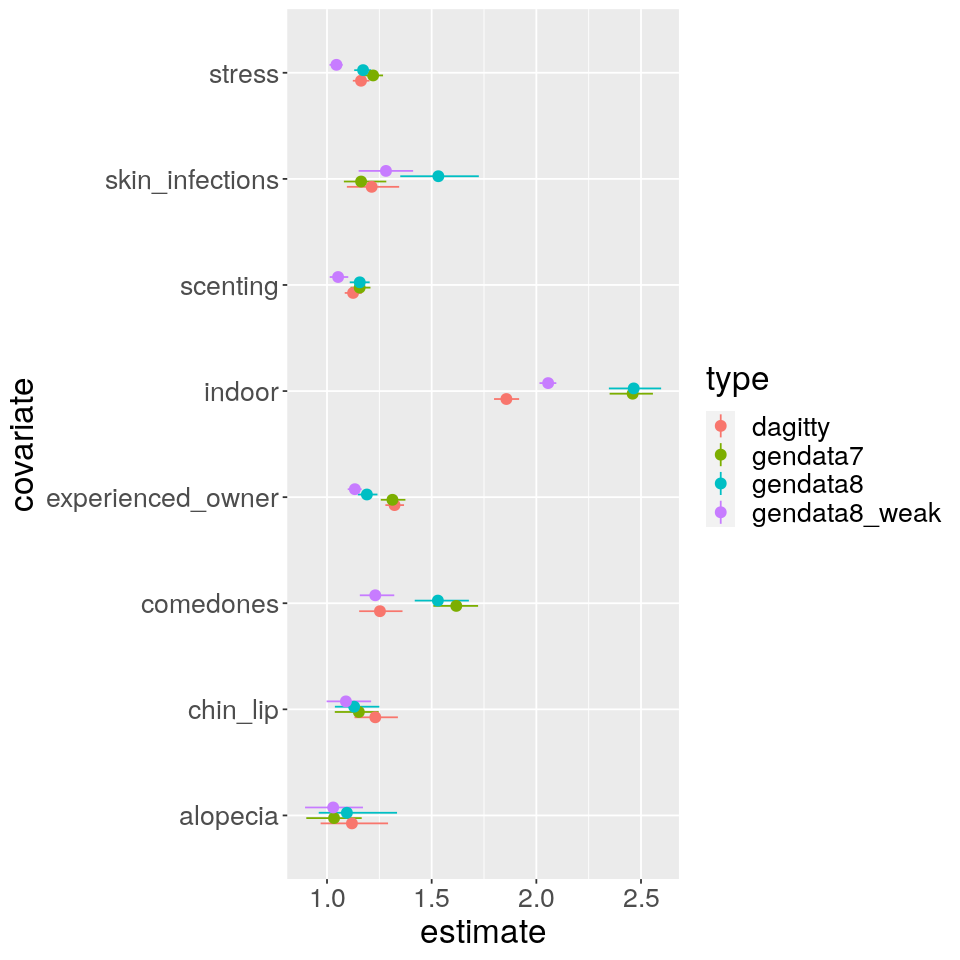

In [44]:
ggplot(T2_plot, aes(x=covariate,y=estimate,ymin=left,ymax=right,color=type)) +
    geom_pointrange(position = position_dodge2(width = 0.2)) + 
    theme(text = element_text(size = 20)) +
    coord_flip()

##### example 2) outcome: skin infections

In [45]:
# the whole population
m1_pop  <- glm(skin_infections ~ 1 
               + alopecia 
               + comedones           
               + scenting     
               + stress       
               + indoor,
             data = mydataSEM, family = binomial)
m2_pop  <- glm(skin_infections ~ 1 
               + comedones           
               + scenting     
               + stress       
               + indoor,
             data = mydataSEM, family = binomial)
m3_pop  <- glm(skin_infections ~ 1 
               + scenting     
               + stress       
               + indoor,
             data = mydataSEM, family = binomial)
m4_pop  <- glm(skin_infections ~ 1 
               + stress       
               + indoor,
             data = mydataSEM, family = binomial)
m5_pop  <- glm(skin_infections ~ 1 
               + indoor,
             data = mydataSEM, family = binomial)

# consulted pets only
m1_cons <- glm(skin_infections ~ 1 
               + alopecia 
               + comedones           
               + scenting     
               + stress       
               + indoor,
             data = mydata_consult1, family = binomial)
m2_cons  <- glm(skin_infections ~ 1 
                + comedones           
                + scenting     
                + stress       
                + indoor            ,
             data = mydata_consult1, family = binomial)
m3_cons  <- glm(skin_infections ~ 1 
                + scenting     
                + stress       
                + indoor,
             data = mydata_consult1, family = binomial)
m4_cons  <- glm(skin_infections ~ 1 
                + stress       
                + indoor,
             data = mydata_consult1, family = binomial)
m5_cons  <- glm(skin_infections ~ 1 
                + indoor,
             data = mydata_consult1, family = binomial)

In [46]:
v  <- list('alopecia',m1_pop,'comedones',m2_pop,'scenting',m3_pop,'stress',m4_pop,'indoor',m5_pop)
T2 <- createT2(v)
# since it is logistic, exponentiate and create CI
T2$'exp_reg_coeff' <- exp(T2$'reg_coeff')
T2$'CI_left'       <- exp(T2$'reg_coeff'-1.96*T2$'std_error')
T2$'CI_right'      <- exp(T2$'reg_coeff'+1.96*T2$'std_error')
#read the coefficients into the data frame 
T2$modeltype <- 'T2 -> skin inf, population'
e2 <- T2
v  <- list('alopecia',m1_cons,'comedones',m2_cons,'scenting',m3_cons,'stress',m4_cons,'indoor',m5_cons)
T2 <- createT2(v)
# since it is logistic, exponentiate and create CI
T2$'exp_reg_coeff' <- exp(T2$'reg_coeff')
T2$'CI_left'       <- exp(T2$'reg_coeff'-1.96*T2$'std_error')
T2$'CI_right'      <- exp(T2$'reg_coeff'+1.96*T2$'std_error')
#read the coefficients into the data frame 
T2$modeltype <- 'T2 -> skin inf, consultation'

e2 <- rbind(e2,T2)

In [47]:
gendata7      <- read.csv('gendata7/example2.csv')
gendata8      <- read.csv('gendata8/example2.csv')
gendata8_weak <- read.csv('gendata8_weaker_dag/example2.csv')
                     
gendata7 <- aggregate(gendata7[,c('exp_reg_coeff')],
                      by=list(modeltype=gendata7$modeltype,covariate=gendata7$covariate, 
                              adjusted_for=gendata7$adjusted_for),
                      function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))
                      
gendata8 <- aggregate(gendata8[,c('exp_reg_coeff')],
                      by=list(modeltype=gendata8$modeltype,covariate=gendata8$covariate, 
                              adjusted_for=gendata8$adjusted_for),
                      function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))

gendata8_weak <- aggregate(gendata8_weak[,c('exp_reg_coeff')],
                           by=list(modeltype=gendata8_weak$modeltype,covariate=gendata8_weak$covariate, 
                              adjusted_for=gendata8_weak$adjusted_for),
                           function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))                   

# get all results together
e2 <- merge(e2[,c("modeltype", "covariate",'adjusted_for', 'exp_reg_coeff','CI_left','CI_right')], gendata7, 
            by=c("modeltype", "covariate",'adjusted_for'))
                           
e2 <- merge(e2, gendata8, by=c("modeltype", "covariate",'adjusted_for'))
                           
e2 <- merge(e2, gendata8_weak, by=c("modeltype", "covariate",'adjusted_for'))                           
colnames(e2) <- c('modeltype','covariate','adjusted_for','exp_reg_coeff','CI_left','CI_right',
                  'gendata7',
                  'gendata8',
                  'gendata8_weak')

In [48]:
e2

modeltype,covariate,adjusted_for,exp_reg_coeff,CI_left,CI_right,gendata7,gendata8,gendata8_weak
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,"<dbl[,3]>","<dbl[,3]>","<dbl[,3]>"
"T2 -> skin inf, consultation",alopecia,"comedones, scenting, stress, indoor",1.6187370,0.9414235,2.783348,"1.6323210, 2.3155859, 3.2926225","1.6457691, 2.3190089, 3.3090562","1.0805627, 1.8549065, 2.8328147"
"T2 -> skin inf, consultation",comedones,"scenting, stress, indoor",3.1832883,2.4141103,4.197540,"10.6236195, 15.8767169, 21.3716649","9.0371824, 11.7779505, 15.8095203","9.6300118, 12.2661819, 15.0454645"
"T2 -> skin inf, consultation",indoor,,0.9606861,0.8003112,1.153199,"0.6835544, 0.8180072, 0.9644555","0.6400409, 0.7391259, 0.8745959","0.6696695, 0.8136800, 0.9382721"
"T2 -> skin inf, consultation",scenting,"stress, indoor",1.7223480,1.4253060,2.081295,"2.4568699, 3.0085341, 3.6348199","2.5249777, 3.0145783, 3.7299913","1.3887305, 1.7312306, 2.1177256"
"T2 -> skin inf, consultation",stress,indoor,1.7312293,1.4464436,2.072085,"3.1902377, 3.8169798, 4.3863080","2.8528989, 3.5658094, 4.3525501","1.7750502, 2.1358285, 2.6291888"
"T2 -> skin inf, population",alopecia,"comedones, scenting, stress, indoor",2.0168881,1.5381449,2.644639,"1.9669884, 2.4831401, 2.9293569","2.0138226, 2.4674774, 2.9793274","1.4713296, 2.0120114, 2.5390998"
"T2 -> skin inf, population",comedones,"scenting, stress, indoor",3.7853887,3.2759817,4.374007,"12.0701946, 17.8388904, 21.6735386","11.1132161, 13.6979384, 17.2757281","11.9576562, 13.5721470, 15.4164499"
"T2 -> skin inf, population",indoor,,0.9147248,0.8252351,1.013919,"0.8083641, 0.8774058, 0.9912068","0.7432822, 0.8192022, 0.9196232","0.7464990, 0.8156493, 0.8936170"
"T2 -> skin inf, population",scenting,"stress, indoor",1.9065514,1.7308694,2.100065,"2.7841021, 3.0776869, 3.4939886","2.8585965, 3.2474642, 3.7607544","1.6261829, 1.8031848, 1.9697068"


In [49]:
#this should not be pasted but will have to do for now
e2_plot <- data.frame(type='dagitty',
                      modeltype=e2$modeltype,
                      covariate=e2$covariate,
                      left=e2$CI_left,
                      estimate=e2$exp_reg_coeff,
                      right=e2$CI_right)

e2_plot <- rbind(e2_plot,data.frame(type='gendata7',
                                    modeltype=e2$modeltype,
                                    covariate=e2$covariate,
                                    left=e2$gendata7[,1],
                                    estimate=e2$gendata7[,2],
                                    right=e2$gendata7[,3]))

e2_plot <- rbind(e2_plot,data.frame(type='gendata8',
                                    modeltype=e2$modeltype,
                                    covariate=e2$covariate,
                                    left=e2$gendata8[,1],
                                    estimate=e2$gendata8[,2],
                                    right=e2$gendata8[,3]))

e2_plot <- rbind(e2_plot,data.frame(type='gendata8_weak',
                                    modeltype=e2$modeltype,
                                    covariate=e2$covariate,
                                    left=e2$gendata8_weak[,1],
                                    estimate=e2$gendata8_weak[,2],
                                    right=e2$gendata8_weak[,3]))

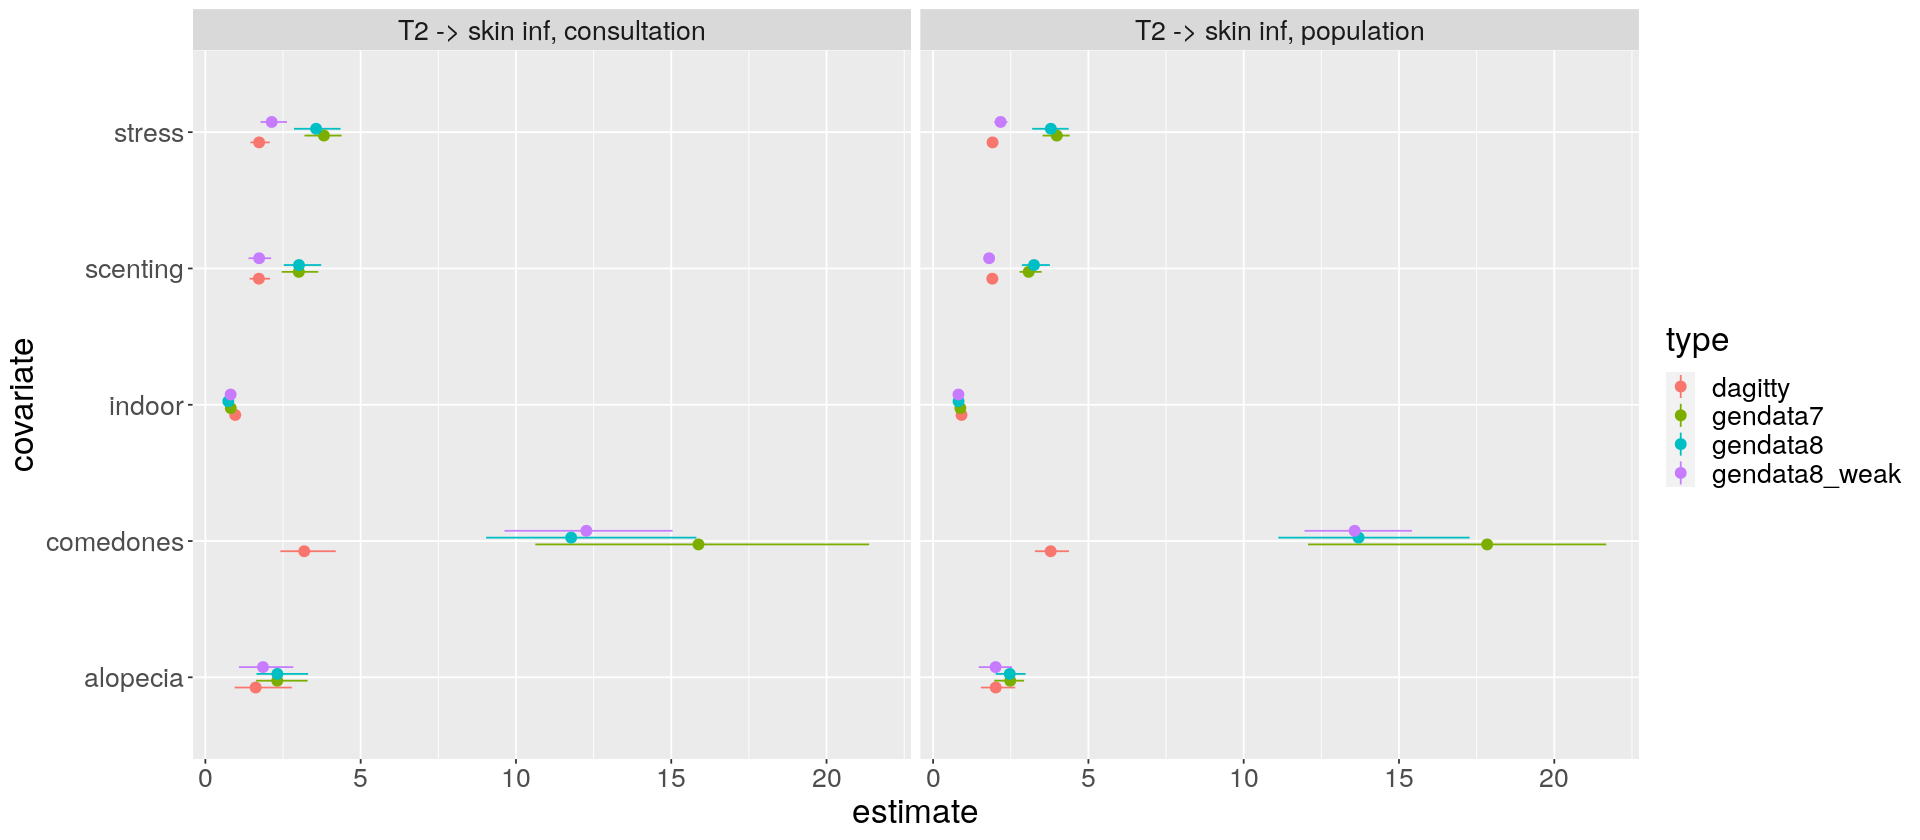

In [50]:
options(repr.plot.width=16, repr.plot.height=7)
ggplot(e2_plot, aes(x=covariate,y=estimate,ymin=left,ymax=right,color=type)) +
    geom_pointrange(position = position_dodge2(width = 0.2)) + 
    theme(text = element_text(size = 20)) +
    coord_flip() +
    facet_wrap(~modeltype)

##### example 3) outcome: acne diagnosis

In [51]:
# examiner
m1_examiner  <- glm(acne_diagnosis ~ 1 + experienced_examiner_j 
                    + experienced_owner   
                    + chin_lip     
                    + skin_infections       
                    + alopecia       
                    + comedones           
                    + scenting     
                    + stress         
                    + indoor,
                    data = mydata_consult1, family = binomial)
m2_examiner  <- glm(acne_diagnosis ~ 1 + experienced_examiner_j 
                    + chin_lip     
                    + skin_infections       
                    + alopecia       
                    + comedones           
                    + scenting     
                    + stress         
                    + indoor,
                    data = mydata_consult1, family = binomial)
m3_examiner  <- glm(acne_diagnosis ~ 1 + experienced_examiner_j 
                    + skin_infections       
                    + alopecia       
                    + comedones           
                    + scenting     
                    + stress         
                    + indoor,
                    data = mydata_consult1, family = binomial)
m4_examiner  <- glm(acne_diagnosis ~ 1 + experienced_examiner_j 
                    + alopecia       
                    + comedones           
                    + scenting     
                    + stress         
                    + indoor,
                    data = mydata_consult1, family = binomial)
m5_examiner  <- glm(acne_diagnosis ~ 1 + experienced_examiner_j 
                    + comedones           
                    + scenting     
                    + stress         
                    + indoor,
                    data = mydata_consult1, family = binomial)
m6_examiner  <- glm(acne_diagnosis ~ 1 + experienced_examiner_j 
                    + scenting     
                    + stress         
                    + indoor,
                    data = mydata_consult1, family = binomial)
m7_examiner  <- glm(acne_diagnosis ~ 1 + experienced_examiner_j 
                    + stress         
                    + indoor,
                    data = mydata_consult1, family = binomial)
m8_examiner  <- glm(acne_diagnosis ~ 1 + experienced_examiner_j 
                    + indoor,
                    data = mydata_consult1, family = binomial)

# cluster
m1_cluster   <- glmer(acne_diagnosis ~ 1 
                      + experienced_owner   
                      + chin_lip     
                      + skin_infections       
                      + alopecia       
                      + comedones           
                      + scenting     
                      + stress         
                      + indoor               
                      + (1|cluster),
                      data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))
m2_cluster   <- glmer(acne_diagnosis ~ 1 
                      + chin_lip     
                      + skin_infections       
                      + alopecia       
                      + comedones           
                      + scenting     
                      + stress         
                      + indoor               
                      + (1|cluster),
                      data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))
m3_cluster   <- glmer(acne_diagnosis ~ 1 
                      + skin_infections       
                      + alopecia       
                      + comedones           
                      + scenting     
                      + stress         
                      + indoor             
                      + (1|cluster),
                      data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))
m4_cluster   <- glmer(acne_diagnosis ~ 1 
                      + alopecia       
                      + comedones           
                      + scenting     
                      + stress         
                      + indoor               
                      + (1|cluster),
                      data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))
m5_cluster   <- glmer(acne_diagnosis ~ 1   
                      + comedones           
                      + scenting     
                      + stress         
                      + indoor              
                      + (1|cluster),
                      data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))
m6_cluster   <- glmer(acne_diagnosis ~ 1 
                      + scenting     
                      + stress         
                      + indoor               
                      + (1|cluster),
                      data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))
m7_cluster   <- glmer(acne_diagnosis ~ 1 
                      + stress         
                      + indoor              
                      + (1|cluster),
                      data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))
m8_cluster   <- glmer(acne_diagnosis ~ 1   
                      + indoor             
                      + (1|cluster),
                      data = mydata_consult1, family = binomial, control = glmerControl(optimizer = "bobyqa"))

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')

boundary (singular) fit: see help('isSingular')



In [52]:
v <- list('experienced_owner',m1_examiner,
          'chin_lip',m2_examiner,
          'skin_infections',m3_examiner,
          'alopecia',m4_examiner,
          'comedones',m5_examiner,
          'scenting',m6_examiner,
          'stress',m7_examiner,
          'indoor',m8_examiner)

T2 <- createT2(v)
# since it is logistic, exponentiate and create CI
T2$'exp_reg_coeff' <- exp(T2$'reg_coeff')
T2$'CI_left'       <- exp(T2$'reg_coeff'-1.96*T2$'std_error')
T2$'CI_right'      <- exp(T2$'reg_coeff'+1.96*T2$'std_error')
#read the coefficients into the data frame 
T2$modeltype <- 'T2 -> acne diag, examiner'
e2 <- T2
v <- list('experienced_owner',m1_cluster,
          'chin_lip',m2_cluster,
          'skin_infections',m3_cluster,
          'alopecia',m4_cluster,
          'comedones',m5_cluster,
          'scenting',m6_cluster,
          'stress',m7_cluster,
          'indoor',m8_cluster)
T2 <- createT2(v)
# since it is logistic, exponentiate and create CI
T2$'exp_reg_coeff' <- exp(T2$'reg_coeff')
T2$'CI_left'       <- exp(T2$'reg_coeff'-1.96*T2$'std_error')
T2$'CI_right'      <- exp(T2$'reg_coeff'+1.96*T2$'std_error')
#read the coefficients into the data frame 
T2$modeltype <- 'T2 -> acne diag, cluster'

e2 <- rbind(e2,T2)

In [53]:
# we only want comedones here
gendata7      <- read.csv('gendata7/example3.csv')
gendata8      <- read.csv('gendata8/example3.csv')
gendata8_weak <- read.csv('gendata8_weaker_dag/example3.csv')

                    
gendata7 <- aggregate(gendata7[,c('exp_reg_coeff')],
                      by=list(modeltype=gendata7$modeltype,covariate=gendata7$covariate, 
                              adjusted_for=gendata7$adjusted_for),
                      function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))
                      
gendata8 <- aggregate(gendata8[,c('exp_reg_coeff')],
                      by=list(modeltype=gendata8$modeltype,covariate=gendata8$covariate, 
                              adjusted_for=gendata8$adjusted_for),
                      function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))

gendata8_weak <- aggregate(gendata8_weak[,c('exp_reg_coeff')],
                           by=list(modeltype=gendata8_weak$modeltype,covariate=gendata8_weak$covariate, 
                              adjusted_for=gendata8_weak$adjusted_for),
                           function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))                   

# get all results together
e2 <- merge(e2[,c("modeltype", "covariate",'adjusted_for', 'exp_reg_coeff','CI_left','CI_right')], gendata7, 
            by=c("modeltype", "covariate",'adjusted_for'))
                           
e2 <- merge(e2, gendata8, by=c("modeltype", "covariate",'adjusted_for'))
                           
e2 <- merge(e2, gendata8_weak, by=c("modeltype", "covariate",'adjusted_for'))                           
colnames(e2) <- c('modeltype','covariate','adjusted_for','exp_reg_coeff','CI_left','CI_right',
                  'gendata7',
                  'gendata8',
                  'gendata8_weak')

In [54]:
e2

modeltype,covariate,adjusted_for,exp_reg_coeff,CI_left,CI_right,gendata7,gendata8,gendata8_weak
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,"<dbl[,3]>","<dbl[,3]>","<dbl[,3]>"
"T2 -> acne diag, cluster",alopecia,"comedones, scenting, stress, indoor",0.7274879,0.2186423,2.420569,"0.3360822, 0.9985493, 1.951763","0.5521166, 1.1131415, 1.892253","0.08645470, 0.8559702, 2.293322"
"T2 -> acne diag, cluster",chin_lip,"skin_infections, alopecia, comedones, scenting, stress, indoor",19.3157626,11.7827570,31.664803,"11.0654798, 28.7797225, 111.807265","24.6843833, 75.5633730, 217.007908","21.29177119, 65.2640929, 234.489459"
"T2 -> acne diag, cluster",comedones,"scenting, stress, indoor",27.2183687,17.4749167,42.394456,"37.2890635, 63.4801319, 140.447948","38.2974280, 66.8831845, 128.651657","34.82436739, 53.2745361, 104.779679"
"T2 -> acne diag, cluster",experienced_owner,"chin_lip, skin_infections, alopecia, comedones, scenting, stress, indoor",5.8857528,2.0360817,17.014095,"0.1830766, 0.4038302, 1.016761","0.2263098, 0.4484323, 1.111491","0.28222973, 0.6794321, 1.166305"
"T2 -> acne diag, cluster",indoor,,1.9366243,1.2855986,2.917329,"1.3941407, 2.1653629, 2.912585","1.3328977, 1.9293446, 2.784068","1.11022552, 1.7004550, 2.291980"
"T2 -> acne diag, cluster",scenting,"stress, indoor",3.1664040,1.9983768,5.017129,"3.3985098, 5.2507332, 10.667321","3.2507583, 6.3463942, 13.553452","3.22665372, 5.2800778, 9.547445"
"T2 -> acne diag, cluster",skin_infections,"alopecia, comedones, scenting, stress, indoor",2.2196455,1.1195607,4.400678,"0.7251825, 1.1162625, 1.915159","0.8298931, 1.2337022, 2.075471","0.58066153, 1.0102603, 1.803289"
"T2 -> acne diag, cluster",stress,indoor,5.2298322,3.3568454,8.147871,"5.1961588, 7.8653643, 13.123624","5.3278118, 7.6155606, 12.665647","2.50242877, 4.0034646, 6.323097"
"T2 -> acne diag, examiner",alopecia,"experienced_examiner_j, comedones, scenting, stress, indoor",0.7346458,0.2207453,2.444920,"0.3381656, 1.0093043, 1.892624","0.5533984, 1.1095232, 1.913329","0.08610713, 0.8597710, 2.285999"


In [55]:
#this should not be pasted but will have to do for now
e2_plot <- data.frame(type='dagitty',
                      modeltype=e2$modeltype,
                      covariate=e2$covariate,
                      left=e2$CI_left,
                      estimate=e2$exp_reg_coeff,
                      right=e2$CI_right)

e2_plot <- rbind(e2_plot,data.frame(type='gendata7',
                                    modeltype=e2$modeltype,
                                    covariate=e2$covariate,
                                    left=e2$gendata7[,1],
                                    estimate=e2$gendata7[,2],
                                    right=e2$gendata7[,3]))

e2_plot <- rbind(e2_plot,data.frame(type='gendata8',
                                    modeltype=e2$modeltype,
                                    covariate=e2$covariate,
                                    left=e2$gendata8[,1],
                                    estimate=e2$gendata8[,2],
                                    right=e2$gendata8[,3]))

e2_plot <- rbind(e2_plot,data.frame(type='gendata8_weak',
                                    modeltype=e2$modeltype,
                                    covariate=e2$covariate,
                                    left=e2$gendata8_weak[,1],
                                    estimate=e2$gendata8_weak[,2],
                                    right=e2$gendata8_weak[,3]))

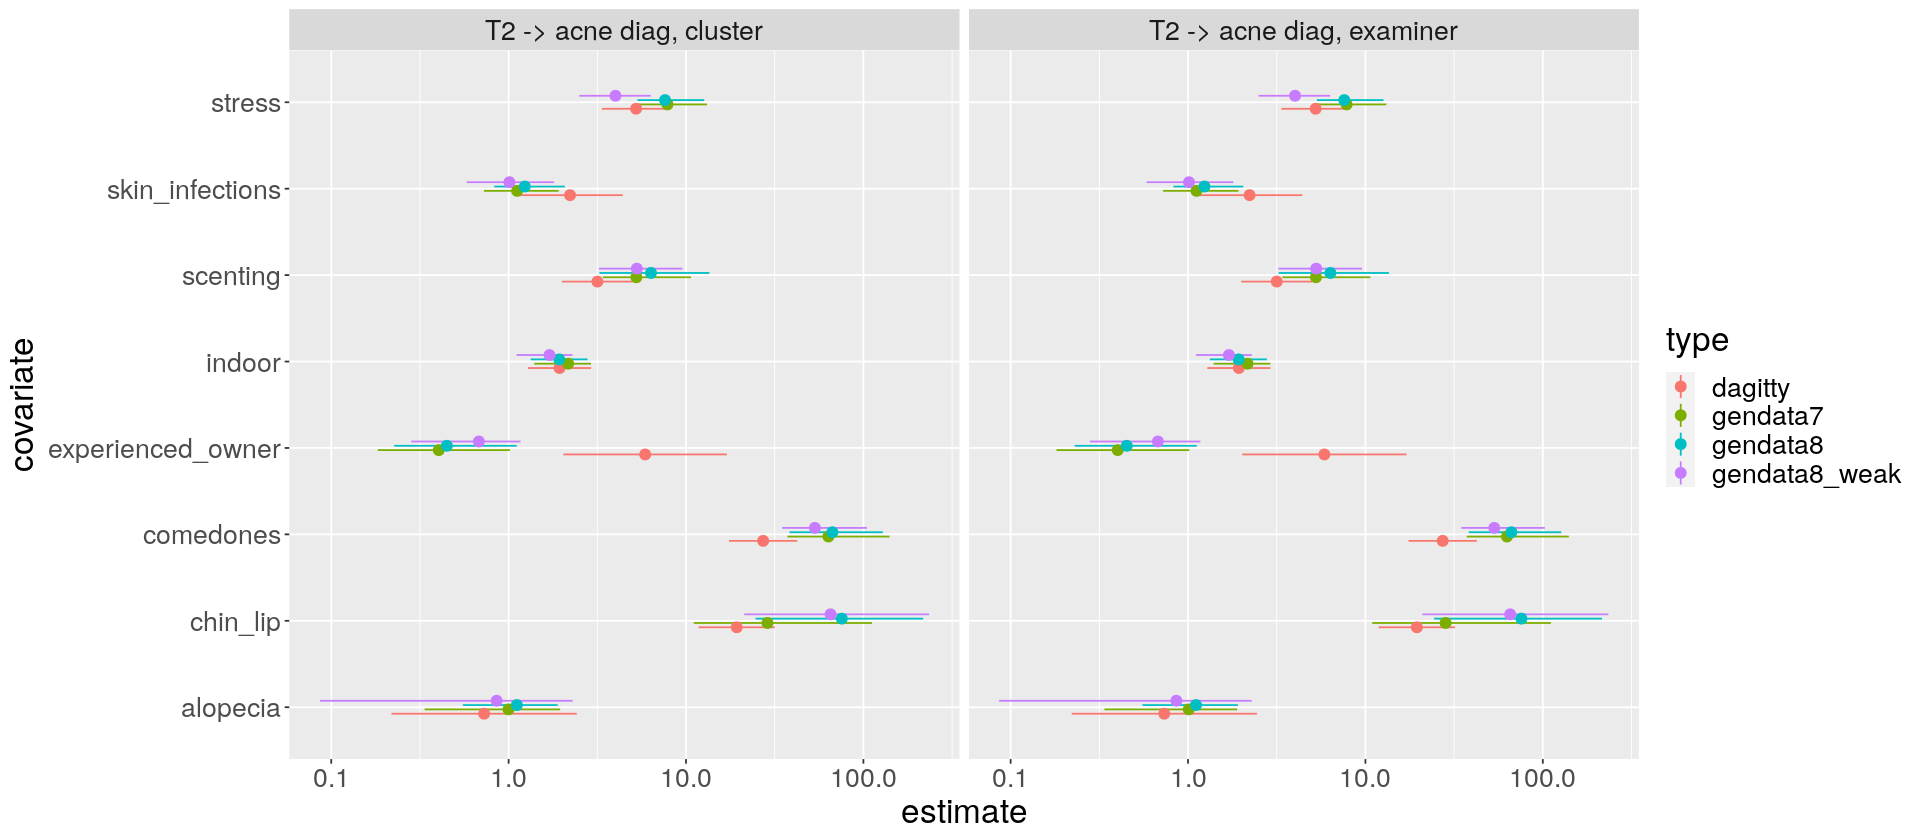

In [56]:
options(repr.plot.width=16, repr.plot.height=7)
ggplot(e2_plot, aes(x=covariate,y=estimate,ymin=left,ymax=right,color=type)) +
    geom_pointrange(position = position_dodge2(width = 0.2)) + 
    theme(text = element_text(size = 20)) +
    coord_flip() +
    facet_wrap(~modeltype) +
    scale_y_continuous(trans='log10')

In [57]:
head(e2_plot,20)

,type,modeltype,covariate,left,estimate,right
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,dagitty,"T2 -> acne diag, cluster",alopecia,0.2186423,0.7274879,2.420569
2,dagitty,"T2 -> acne diag, cluster",chin_lip,11.7827570,19.3157626,31.664803
3,dagitty,"T2 -> acne diag, cluster",comedones,17.4749167,27.2183687,42.394456
4,dagitty,"T2 -> acne diag, cluster",experienced_owner,2.0360817,5.8857528,17.014095
5,dagitty,"T2 -> acne diag, cluster",indoor,1.2855986,1.9366243,2.917329
6,dagitty,"T2 -> acne diag, cluster",scenting,1.9983768,3.1664040,5.017129
7,dagitty,"T2 -> acne diag, cluster",skin_infections,1.1195607,2.2196455,4.400678
8,dagitty,"T2 -> acne diag, cluster",stress,3.3568454,5.2298322,8.147871
9,dagitty,"T2 -> acne diag, examiner",alopecia,0.2207453,0.7346458,2.444920


#### Prevalence tables

In [58]:
mydata_consult0 <- mydataSEM[mydataSEM$consultation==0,]
mydata_consult1 <- mydataSEM[mydataSEM$consultation==1,]

In [59]:
num_consult0 <- nrow(mydata_consult0)
num_consult1 <- nrow(mydata_consult1)
print(num_consult0)
print(num_consult1)

[1] 78300
[1] 21700


In [60]:
prevalence_dagitty <- get_prevalence(mydataSEM)

In [61]:
head(prevalence_dagitty)

,covariate,dataset,percentage1
,<chr>,<chr>,<dbl>
1,experienced_owner,consulted,40.17
2,chin_lip,consulted,3.92
3,skin_infections,consulted,2.38
4,alopecia,consulted,1.23
5,comedones,consulted,3.89
6,scenting,consulted,28.10


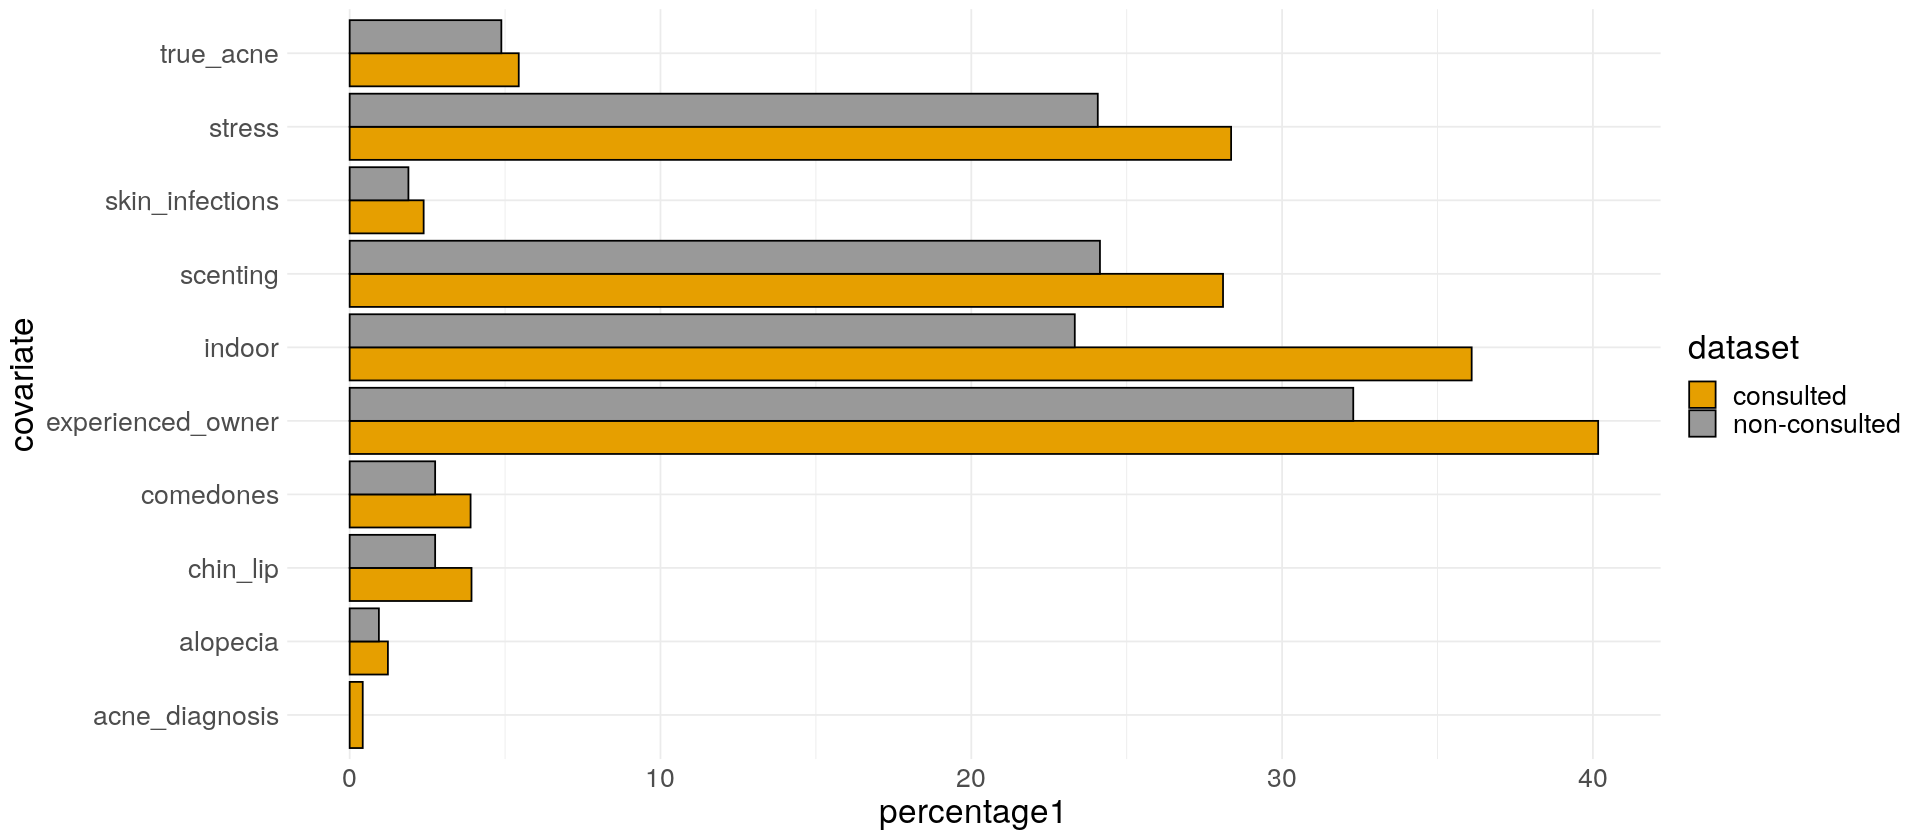

In [62]:
ggplot(data=prevalence_dagitty, aes(x=covariate, y=percentage1, fill=dataset)) +
geom_bar(stat="identity", color="black", position=position_dodge()) +
  theme_minimal() + scale_fill_manual(values=c('#E69F00','#999999')) +
  theme(text = element_text(size = 20)) +
  coord_flip()

In [63]:
gendata7      <- read.csv('gendata7/prevalence.csv')
gendata8      <- read.csv('gendata8/prevalence.csv')
gendata8_weak <- read.csv('gendata8_weaker_dag/prevalence.csv')
                     
gendata7 <- aggregate(gendata7[,c('percentage1')],
                      by=list(dataset=gendata7$dataset,covariate=gendata7$covariate),
                      function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))
                      
gendata8 <- aggregate(gendata8[,c('percentage1')],
                      by=list(dataset=gendata8$dataset,covariate=gendata8$covariate),
                      function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))

gendata8_weak <- aggregate(gendata8_weak[,c('percentage1')],
                           by=list(dataset=gendata8_weak$dataset,covariate=gendata8_weak$covariate),
                           function(i, na.rm) quantile(i, probs=c(0.025,0.5,0.975)))                   

# get all results together

e2 <- merge(prevalence_dagitty, gendata7, by=c("dataset", "covariate"))
                        
e2 <- merge(e2, gendata8, by=c("dataset", "covariate"))
                           
e2 <- merge(e2, gendata8_weak, by=c("dataset", "covariate"))                           
colnames(e2) <- c('dataset','covariate',
                  'dagitty',
                  'gendata7',
                  'gendata8',
                  'gendata8_weak')

In [64]:
e2_plot <- data.frame(type='dagitty',
                        dataset=e2$dataset,
                        covariate=e2$covariate,
                        left=e2$dagitty,
                        prevalence=e2$dagitty,
                        right=e2$dagitty)

e2_plot <- rbind(e2_plot,data.frame(type='gendata7',
                                    dataset=e2$dataset,
                                    covariate=e2$covariate,
                                    left=e2$gendata7[,1],
                                    prevalence=e2$gendata7[,2],
                                    right=e2$gendata7[,3]))

e2_plot <- rbind(e2_plot,data.frame(type='gendata8',
                                    dataset=e2$dataset,
                                    covariate=e2$covariate,
                                    left=e2$gendata8[,1],
                                    prevalence=e2$gendata8[,2],
                                    right=e2$gendata8[,3]))

e2_plot <- rbind(e2_plot,data.frame(type='gendata8_weak',
                                    dataset=e2$dataset,
                                    covariate=e2$covariate,
                                    left=e2$gendata8_weak[,1],
                                    prevalence=e2$gendata8_weak[,2],
                                    right=e2$gendata8_weak[,3]))

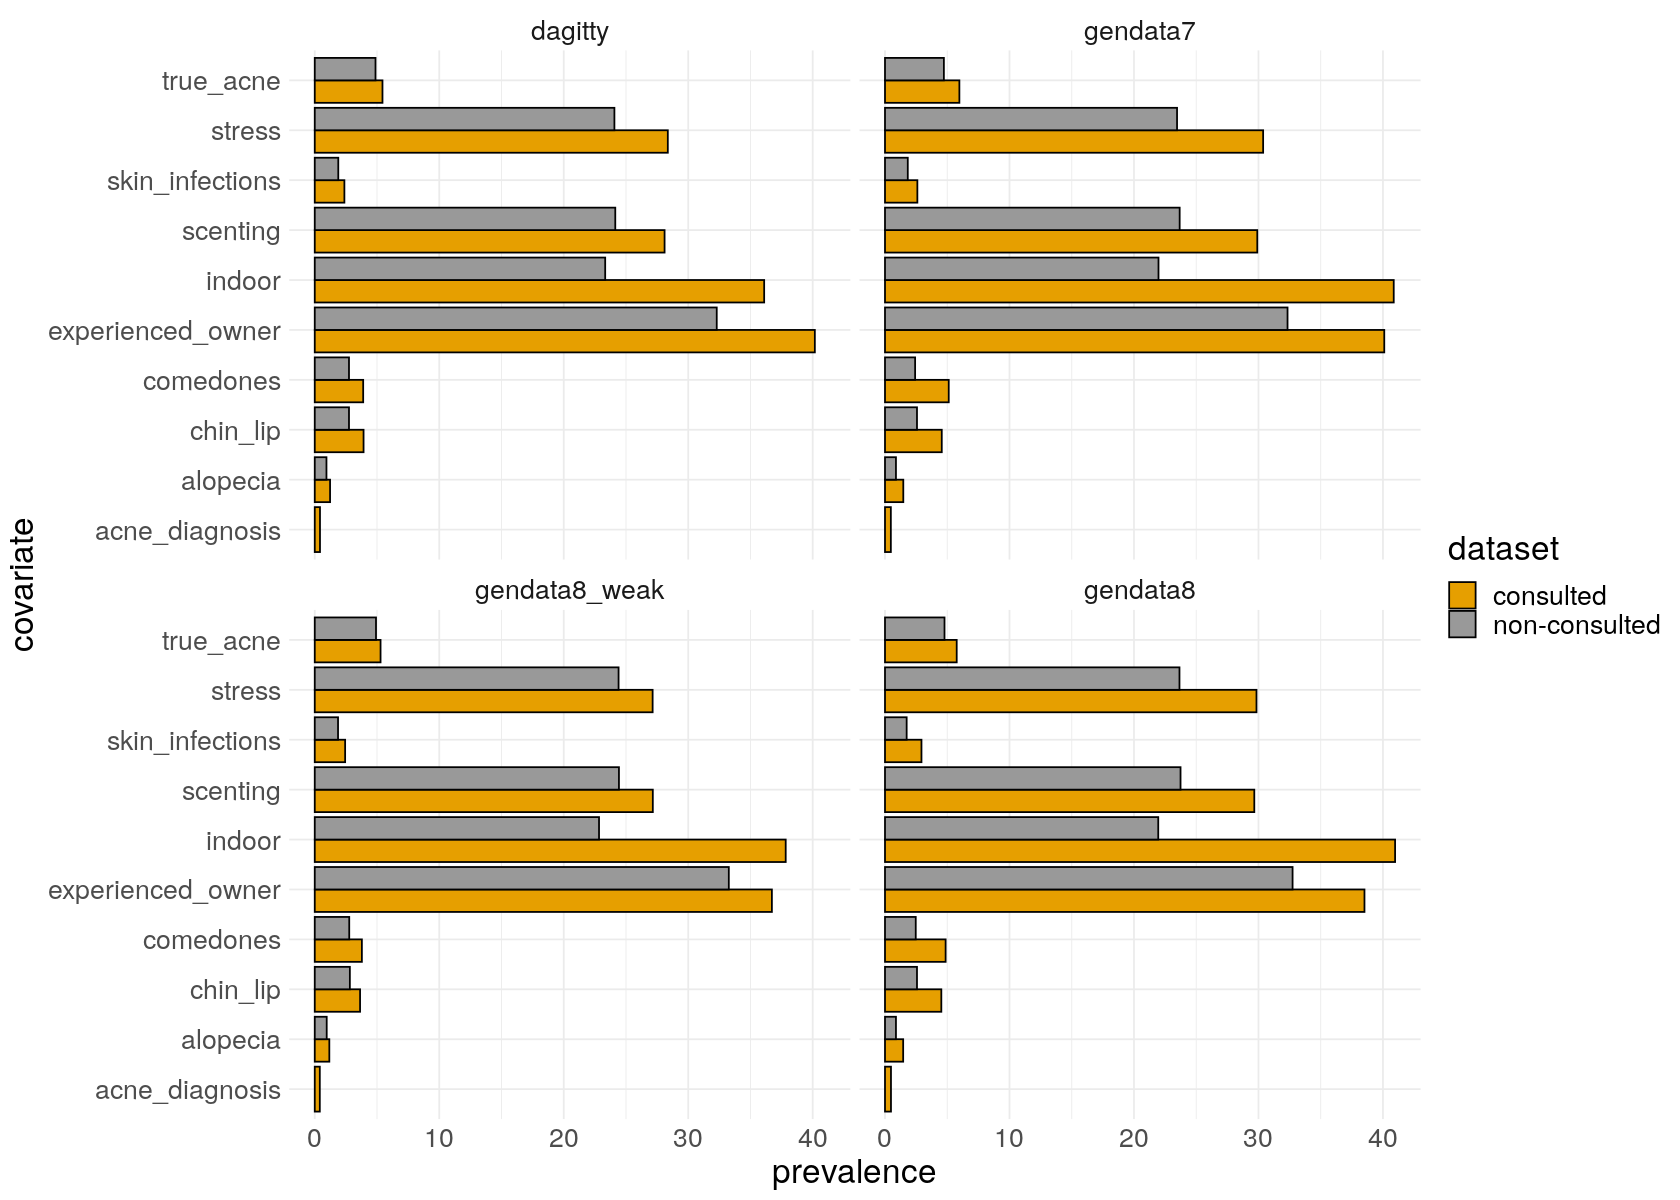

In [65]:
options(repr.plot.width=14, repr.plot.height=10)
#transforming the order of the plots
ggplot(transform(e2_plot, type=factor(type,levels=c("dagitty","gendata7","gendata8_weak","gendata8"))),
       aes(x=covariate,y=prevalence,fill=dataset)) +
    geom_bar(stat="identity", color="black", position=position_dodge()) +
    theme_minimal() + scale_fill_manual(values=c('#E69F00','#999999')) +    
    theme(text = element_text(size = 20)) +
    coord_flip() +
    facet_wrap(~type)

In [66]:
head(e2_plot,20)

,type,dataset,covariate,left,prevalence,right
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,dagitty,consulted,acne_diagnosis,0.42000,0.42,0.42000
2,dagitty,consulted,alopecia,1.23000,1.23,1.23000
3,dagitty,consulted,chin_lip,3.92000,3.92,3.92000
4,dagitty,consulted,comedones,3.89000,3.89,3.89000
5,dagitty,consulted,experienced_owner,40.17000,40.17,40.17000
6,dagitty,consulted,indoor,36.10000,36.10,36.10000
7,dagitty,consulted,scenting,28.10000,28.10,28.10000
8,dagitty,consulted,skin_infections,2.38000,2.38,2.38000
9,dagitty,consulted,stress,28.36000,28.36,28.36000
